<a href="https://colab.research.google.com/github/niteshbansal07/phys3130_nb/blob/main/HW4_nitesh_bansal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phys 3130

#HW4: Train-test Split and Cross-Validation Lab

Author: Dr. Elaina A. Hyde

Due Date: April 02, 2025 10pm

-----

This notebook is a guided code including all questions for HW4. Students should make a copy and enter their solutions, avoiding copy-paste from online or Gemini. Please note, this is partial 'AI autocomplete' assignment, you are free to use any (cited) web references. If you have AI generated code, make SURE that you have explained and cited it, and leave in your prompt as well as your original contribution (use the hashtag to include comments in your code).

### How to turn in this homework:
* **Step 1:** make a copy in your local google drive of this notebook and rename it to HW4_firstname_lastname.ipynb

* **Step 2:** go to your GitHub account and select the private class repo you created.

* **Step 3:** Load your .ipynb file into your private github

* **Step 4:** your upload date timestamp is your due date check, do not upload past the deadline or you will lose marks of 10% for every hour late.
---
Student name: [Nitesh Bansal]

---
## Review of train/test validation methods

We've discussed basic models.

Make sure to review overfitting, underfitting, and how to validate the "generalizeability" of your models by testing them on unseen data.

In this homework you'll practice two related validation methods:
1. **train/test split**
2. **k-fold cross-validation**

Train/test split and k-fold cross-validation both serve two useful purposes:
- We prevent overfitting by not using all the data, and
- We retain some remaining data to evaluate our model.

In the case of cross-validation, the model fitting and evaluation is performed multiple times on different train/test splits of the data.

Ultimately we can the training and testing validation framework to compare multiple models on the same dataset. This could be comparisons of two linear models, or of completely different models on the same data.


## Instructions

For your independent practice, fit **three different models** on the Boston housing data. For example, you could pick three different subsets of variables, one or more polynomial models, or any other model that you like.

**Start with train/test split validation:**
* Fix a testing/training split of the data
* Train each of your models on the training data
* Evaluate each of the models on the test data
* Rank the models by how well they score on the testing data set.

**Then try K-Fold cross-validation:**
* Perform a k-fold cross validation and use the cross-validation scores to compare your models. Did this change your rankings?
* Try a few different K-splits of the data for the same models.

If you're interested, try a variety of response variables.  We start with **MEDV** (the `.target` attribute from the dataset load method).

In [1]:
from matplotlib import pyplot as plt

import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

%config InlineBackend.figure_format = 'retina'
%matplotlib inline

plt.style.use('fivethirtyeight')


In [2]:
from sklearn.datasets import fetch_california_housing
#this loads the free california housing data
#remember, why do we NOT want to use the boston set?
#https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html
california = fetch_california_housing()


In [3]:
# Convert to DataFrame for easy manipulation
columns = california.feature_names

#model features and target
X = pd.DataFrame(california.data, columns=california.feature_names)
y = california.target

# Show first few rows of the dataframe
print(X.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  


### Q1. Clean up any data problems

Load the data.  Fix any problems, if applicable.

In [6]:
# California data is from SKlearn so it is reasonably clean
#read up on the columns in SKlearn documentation and enter your solution
#using code and text
print(X.info())
print("Missing values:\n", X.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB
None
Missing values:
 MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64


***Here, we see that the datset is free from mising values and column names are informative, so no further cleanup is needed. One thing I realized was that the median income is in units of tens of thousands of dollars which might seemlike a problem but I would like to keep it that way.***

### Q2. Select 3-4 variables with your dataset to perform a 50/50 test train split on

- Use sklearn.
- Score and plot your predictions.

In [7]:
#X.columns will print your column names, as long as you have saved X correctly
print(X.columns)

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude'],
      dtype='object')


In [ ]:
#what does a 50/50 split look like, how about a 80/20 split?
# Hint: Split dataset into training and test sets
#X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=??, random_state=42)

***A 50/50 split means that we are dividing the dataset to use half for training and other half for testing. On the other hand a 80/20 split allocates 80% of samples for training while other 20% for testing.***

The test size here changes, where it is 0.5 for 50/50 split and 0.2 for 80/20 split since only 0.2 of data is used for testing.

Below, I just did a 50/50 split since it wasnt mentioned to do both split.

In [40]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

predictors = ['MedInc','HouseAge', u'AveRooms', 'Population']

#plitting the datasets based on the predictors that are given above using the 50/50 split
data = X[predictors]
target = y

#splitting
X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.5, random_state=42)

#Regression models are ideal for our task, as we’re trying to predict continuous values
#(in this case, house prices). Let's use a simple Linear Regression model to start:

# Instantiate the model
model = LinearRegression()

# Fit the model on training data
model.fit(X_train, y_train)

# Predict values using the test set
y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

#Return the coefficient of determination of the prediction R2
#this can be done 2 ways (probably more)

print("Mean Squared Error: ", mse)
print("R2 Score: ", r2)

Mean Squared Error:  0.6456335073884168
R2 Score:  0.5129020344371453


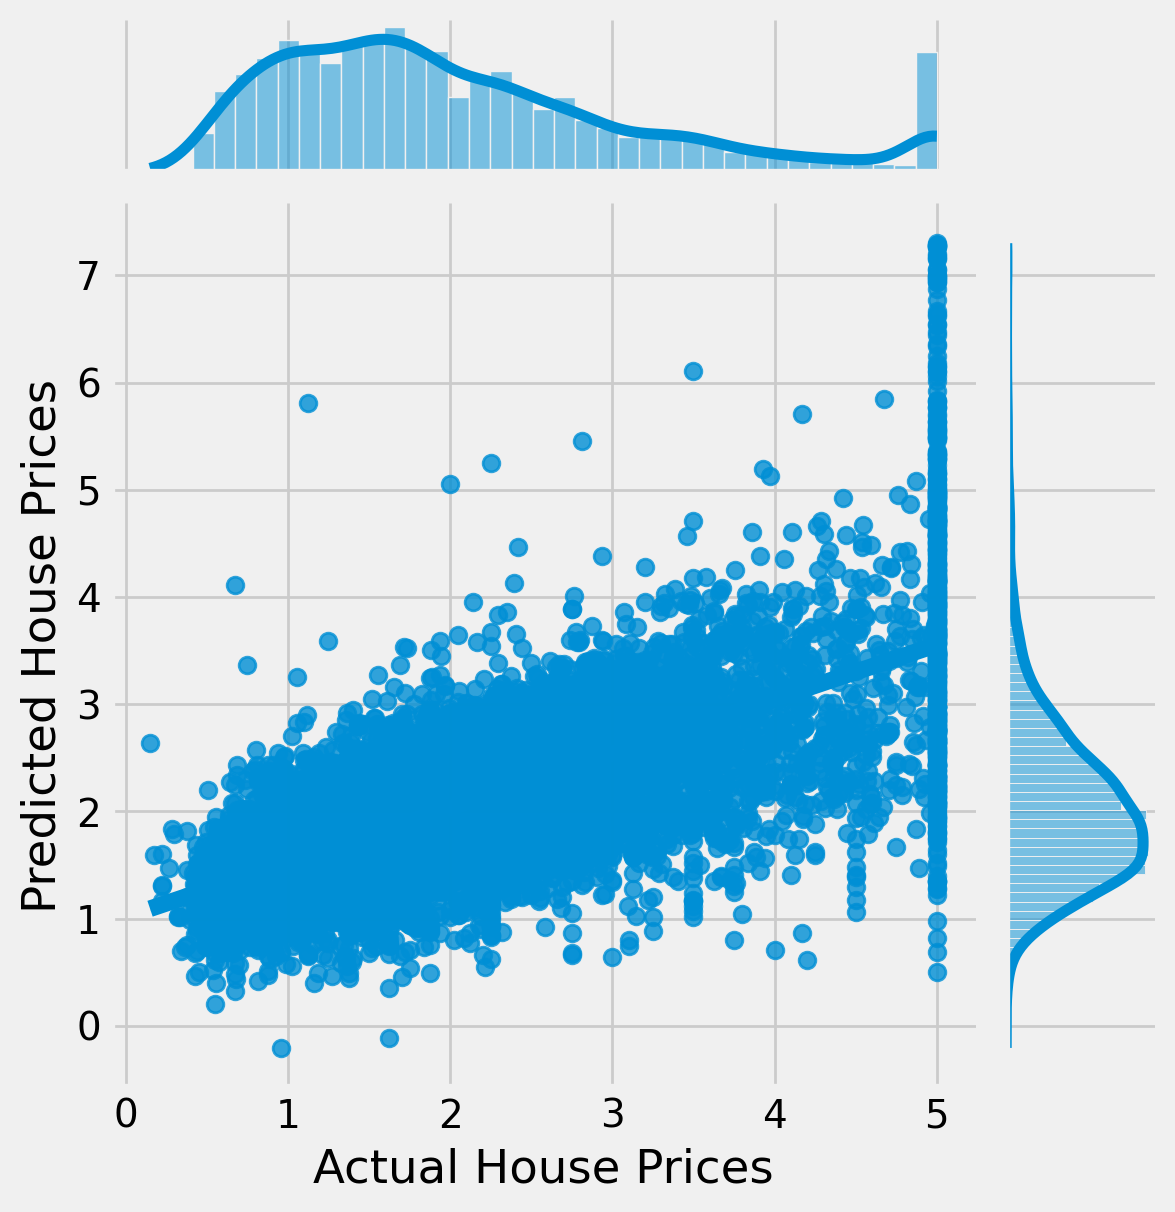

In [41]:
#compare predicted results to test results
#hint: use jointplot
sns.jointplot(x=y_test, y=y_pred, kind="reg")
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.show()

### Q3. Try 70/30 and 90/10 split
- Score and plot.  
- How do your metrics change?

**I would have made a general linear regression function in q2 to cater to 50/50 split nd 80/20 split but the question had certain formatting anf I didnt change it. I am declaring a function here to ease the process.**


Test size: 0.3:
Mean Squared Error:  0.6390322399305919
R2 Score:  0.513133171225564


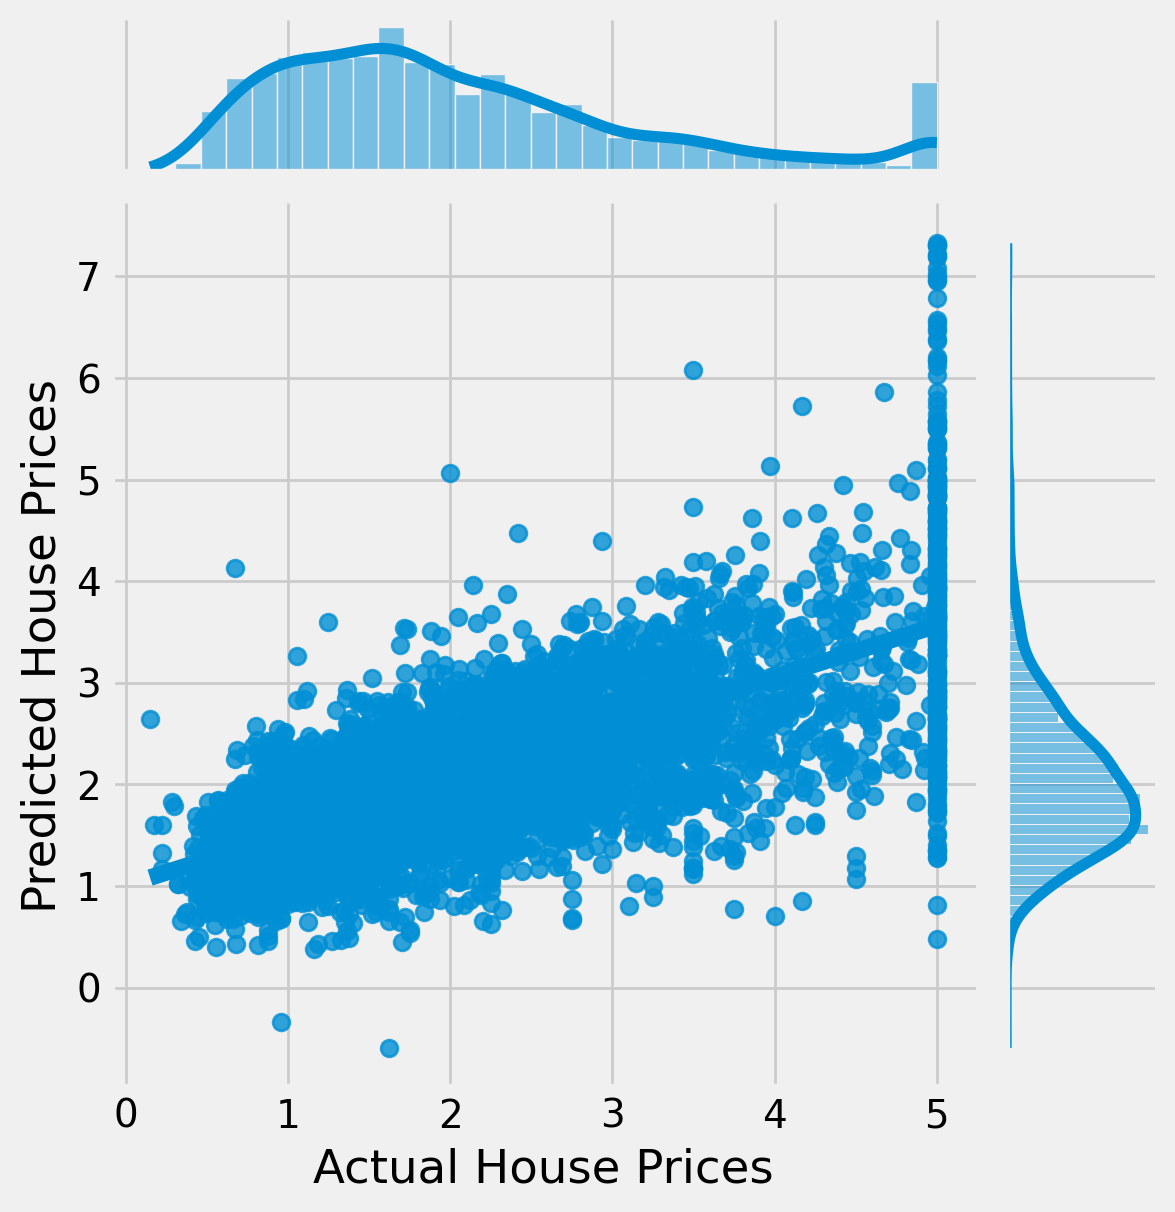


Test size: 0.1:
Mean Squared Error:  0.6847365162101349
R2 Score:  0.48655390536757326


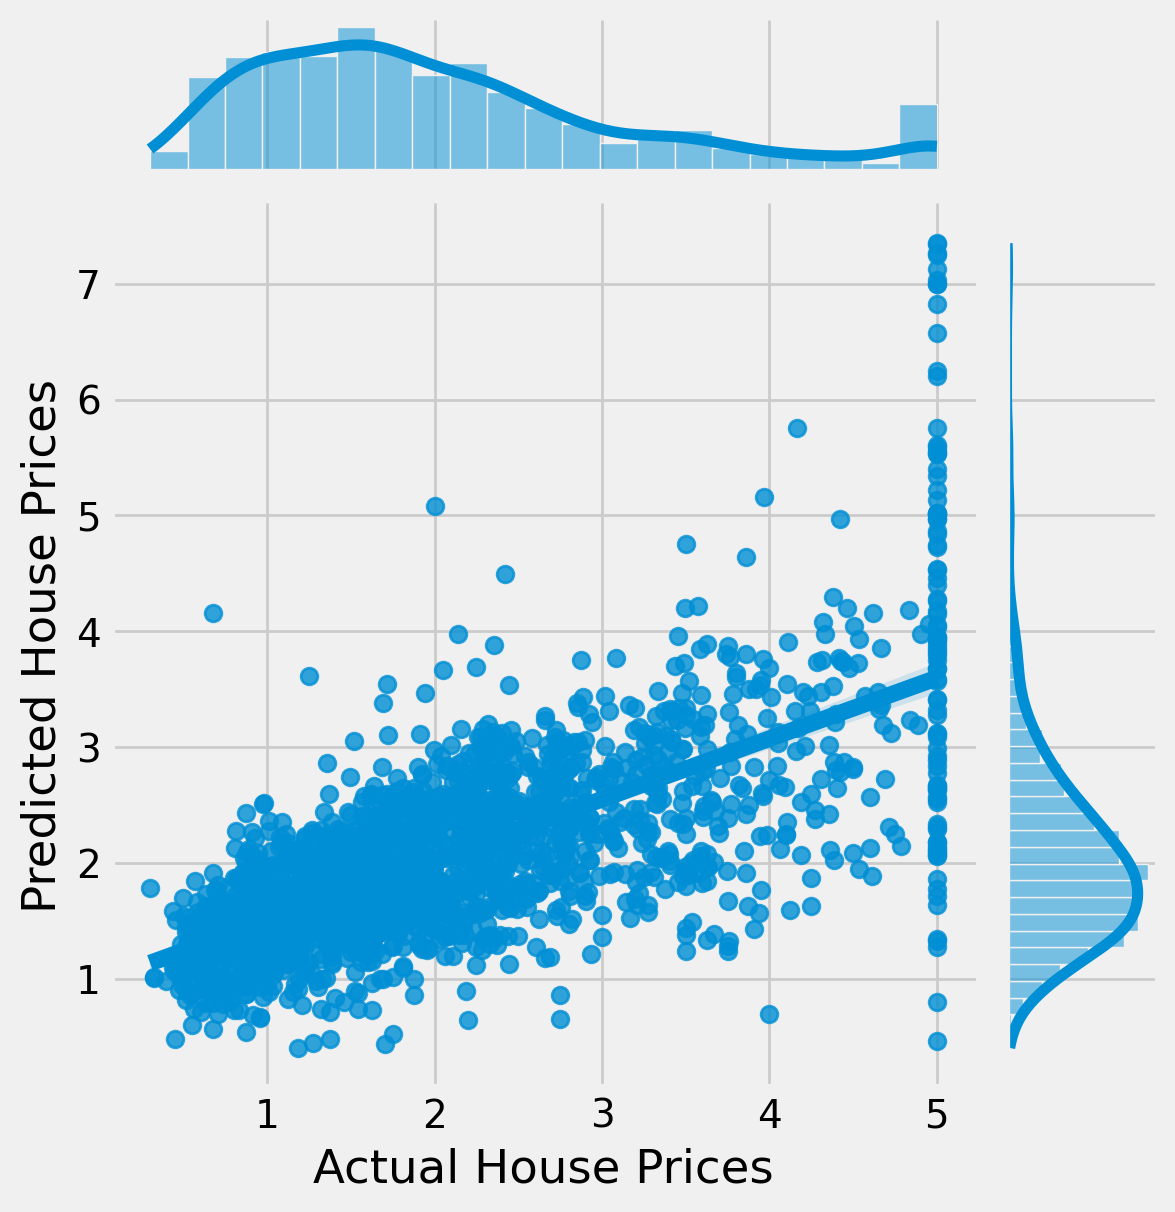

In [42]:
def evaluate_split(test_size, random_state=42):

    #splitting
    X_train, X_test, y_train, y_test  = train_test_split(data, target, test_size=test_size, random_state=random_state)

    #instantiate and fit
    model_split = LinearRegression()
    model_split.fit(X_train, y_train)

    #redcting values
    y_pred_split = model_split.predict(X_test)

    mse = mean_squared_error(y_test , y_pred_split)
    r2 = r2_score(y_test , y_pred_split)

    # Print the evaluation metrics
    print(f"\nTest size: {test_size}:")
    print("Mean Squared Error: ", mse)
    print("R2 Score: ", r2)

    #joinplot
    sns.jointplot(x=y_test , y=y_pred_split, kind="reg")
    plt.xlabel("Actual House Prices")
    plt.ylabel("Predicted House Prices")
    plt.show()

#70/30 splity
evaluate_split(0.3)

#90/10 split
evaluate_split(0.1)

### Q4. Try K-Folds cross-validation with K between 5-10 for your regression.

- What seems optimal?
- How do your scores change?  
- What the variance of scores like?
- Try different folds to get a sense of how this impacts your score.

In [43]:
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn import metrics

# iterate through folds 5-10
for k in range(5, 11):

    # Instantiate the model
    model_cv = LinearRegression()

    # Perform cross-validation
    r2 = cross_val_score(model_cv, data, target, cv=k, scoring='r2')
# Make cross-validated predictions
    print("Cross-Predicted R2:", r2, "for K=", k)
    print("Average R2: ", r2.mean())
    print("Variance: ", r2.var())


Cross-Predicted R2: [0.46128384 0.39667163 0.48347255 0.40402109 0.54720241] for K= 5
Average R2:  0.45853030468545536
Variance:  0.003058037832329146
Cross-Predicted R2: [0.32554395 0.34898461 0.49464634 0.47571015 0.42239981 0.57076964] for K= 6
Average R2:  0.43967575051213137
Variance:  0.00717587690354352
Cross-Predicted R2: [0.39404374 0.40180613 0.52375823 0.46915171 0.21709859 0.33077019
 0.60386875] for K= 7
Average R2:  0.42007104927030553
Variance:  0.01387500441088609
Cross-Predicted R2: [0.43995526 0.42115353 0.48345032 0.46708627 0.52139409 0.37769713
 0.26882748 0.60088788] for K= 8
Average R2:  0.4475564950691053
Variance:  0.008526446273088212
Cross-Predicted R2: [0.46817754 0.455114   0.40012101 0.43284583 0.53566595 0.18492135
 0.40492304 0.41901195 0.49579325] for K= 9
Average R2:  0.42184154712798055
Variance:  0.008744136181262624
Cross-Predicted R2: [0.50581325 0.41316004 0.31604107 0.51211147 0.46355521 0.50241551
 0.07740401 0.36080579 0.28473169 0.42360859] fo

**By looking at the data, we got highest avg R^2 using K=5 with relatively lower variance compared to the highest fold counts. Therefore optimal is 5-fold.**

**We can see that as K goes up, avg R^2 scores lowers and variance goes up.**

**Since a lower fold score has larger training set for each fold, it tends to be more consitent and less variance and vice verse.**

### Q5. Optimize the $R^2$ score

Can you optimize your R^2 by selecting the best features and validating the model using either train/test split or K-Folds?

Your code will need to iterate through the different combinations of predictors, cross-validate the current model parameterization, and determine which set of features performed best.

The number of K-folds is up to you.

> *Hint:* the `itertools` package is useful for combinations and permutations.


In [45]:
from itertools import combinations

best_features = None
best_avg_r2 = -float('inf')
k = 5

# double for loop to make all combos possible
for r in range(1, len(predictors) + 1):
    for combo in combinations(predictors, r):
        #subset
        X_subset = X[list(combo)]

        # usin cross-validation
        model = LinearRegression()
        r2 = cross_val_score(model, X_subset, y, cv=k, scoring='r2')
        avg_r2 = r2.mean()
        var_r2 = r2.var()

        print(f"Features: {combo} -> Average R2: {avg_r2:.3f} and Variance: {var_r2: .3f}")

        # multiple if statements to try to refine the best features
        if avg_r2 > best_avg_r2:
            best_avg_r2 = avg_r2
            best_features = combo
        elif avg_r2 == best_avg_r2:
            if var_r2 < best_var_r2:
                best_var_r2 = var_r2
                best_features = combo
            elif var_r2 == best_var_r2:
                if len(combo) < len(best_features):
                    best_features = combo

print(f"Best Features Combo: {best_features}")

Features: ('MedInc',) -> Average R2: 0.421 and Variance:  0.007
Features: ('HouseAge',) -> Average R2: -0.084 and Variance:  0.006
Features: ('AveRooms',) -> Average R2: -0.084 and Variance:  0.013
Features: ('Population',) -> Average R2: -0.094 and Variance:  0.006
Features: ('MedInc', 'HouseAge') -> Average R2: 0.459 and Variance:  0.003
Features: ('MedInc', 'AveRooms') -> Average R2: 0.422 and Variance:  0.006
Features: ('MedInc', 'Population') -> Average R2: 0.419 and Variance:  0.007
Features: ('HouseAge', 'AveRooms') -> Average R2: -0.079 and Variance:  0.021
Features: ('HouseAge', 'Population') -> Average R2: -0.088 and Variance:  0.007
Features: ('AveRooms', 'Population') -> Average R2: -0.088 and Variance:  0.015
Features: ('MedInc', 'HouseAge', 'AveRooms') -> Average R2: 0.459 and Variance:  0.003
Features: ('MedInc', 'HouseAge', 'Population') -> Average R2: 0.458 and Variance:  0.003
Features: ('MedInc', 'AveRooms', 'Population') -> Average R2: 0.420 and Variance:  0.006
Fea

### Q6 Can you explain what could be wrong with the approach in Question 5?

***Even though I put multiple conditional statements, we are getting multiple combinations for feature and the way i set it up is jus to get the last best but it kind of ignores the fact the there maybe multiple similar to it. This also leads to overfitting and optimism bias as I researched about it. ***

### Q7. Explore another target variable and practice `patsy` formulas

Can you find another response variable, given a combination of predictors, that can be predicted accurately through the exploration of different predictors in this dataset?

**Try out using patsy to construct your target and predictor matrices from formula strings.**

*Tip: Check out pairplots, coefficients, and pearson scores.*

*Tip: For more on patsy models see: https://witve.com/codes/comprehensive-guide-to-patsy-for-building-statistical-models-in-python/*

In [35]:
# Check out variable relations
import seaborn as sns
#sns.pairplot(X) as long as X is defined correctly

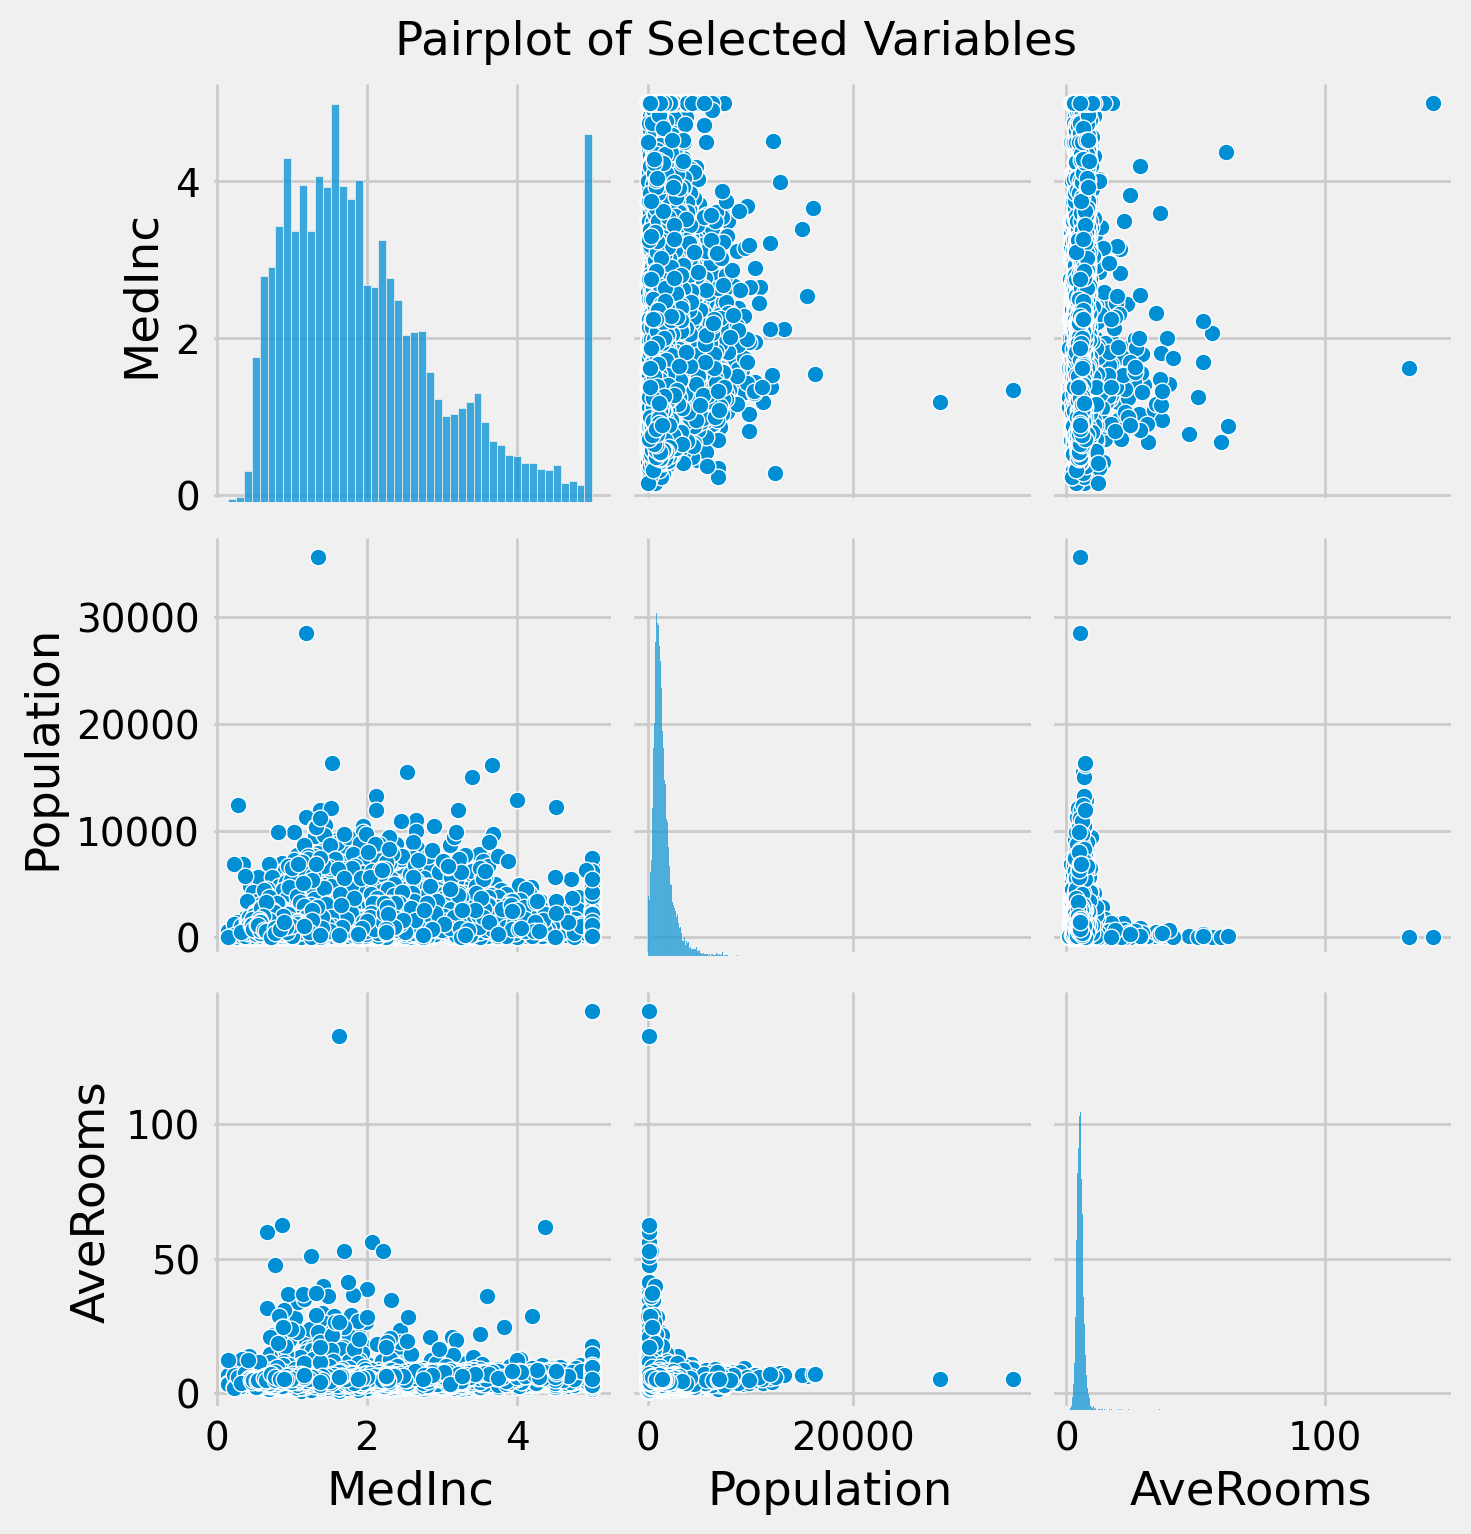

In [36]:
import patsy
df = X.copy()

# Add response to core DataFrame
df['MedInc'] = y

selected_columns = ['MedInc', 'Population', 'AveRooms']
sns.pairplot(df[selected_columns])
plt.suptitle("Pairplot of Selected Variables", y=1.02)
plt.show()

In [37]:
# Easily change your variable predictors without reslicing your DataFrame
#AveBedrooms and AveRooms correlate
#new target variable median income MedInc
yp, Xp = patsy.dmatrices(" MedInc ~ Population + AveRooms", data=df, return_type="dataframe")

# "unravel" y
yp = yp.values.ravel()

#make your train test split
X_train, X_test, y_train, y_test  = train_test_split(data, target, test_size=0.2, random_state=42)

In [39]:
# Build a new model and calculate the score:
lm = LinearRegression()
lm.fit(X_train, y_train)
predictions = lm.predict(X_test)
print("R^2 Score: ", metrics.r2_score(y_test, predictions))

R^2 Score:  0.4980196421223846
